In [22]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('Python:    ', sys.version.split()[0])
print('pandas:    ', pd.__version__)
print('matplotlib:', matplotlib.__version__)
print('seaborn:   ', sns.__version__)

sns.set_theme(style='darkgrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

print(listings.shape)


Python:     3.14.10
pandas:     3.0.5
matplotlib: 3.11.2
seaborn:    0.13.2
(4574, 73)


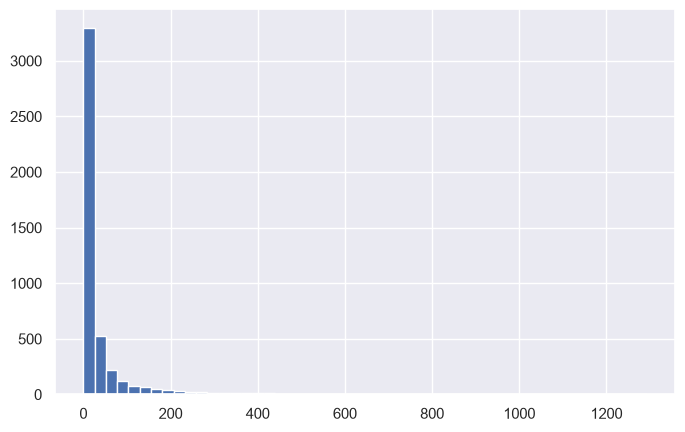

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(listings['number_of_reviews'], bins=50)
plt.show()


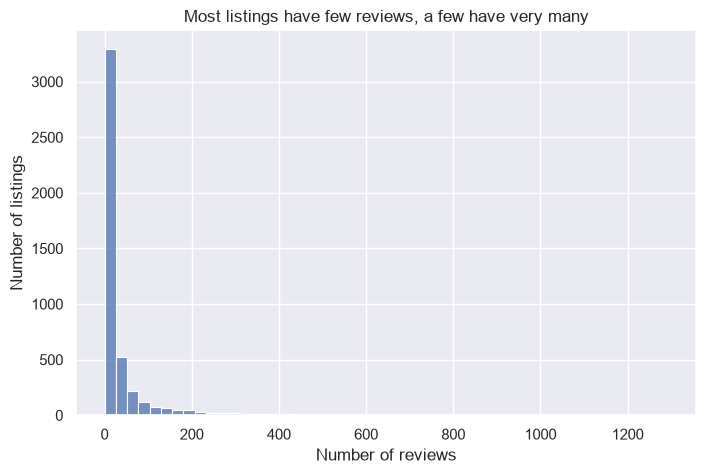

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)
ax.set_title('Most listings have few reviews, a few have very many')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
plt.show()

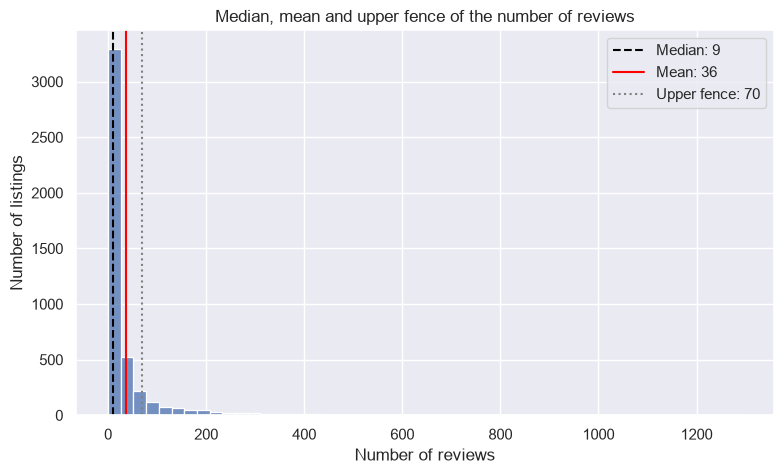

In [25]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median, color='black', linestyle='--', label=f'Median: {median:.0f}')
ax.axvline(mean, color='red', linestyle='-', label=f'Mean: {mean:.0f}')
ax.axvline(upper_fence, color='gray', linestyle=':', label=f'Upper fence: {upper_fence:.0f}')

ax.set_title('Median, mean and upper fence of the number of reviews')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()


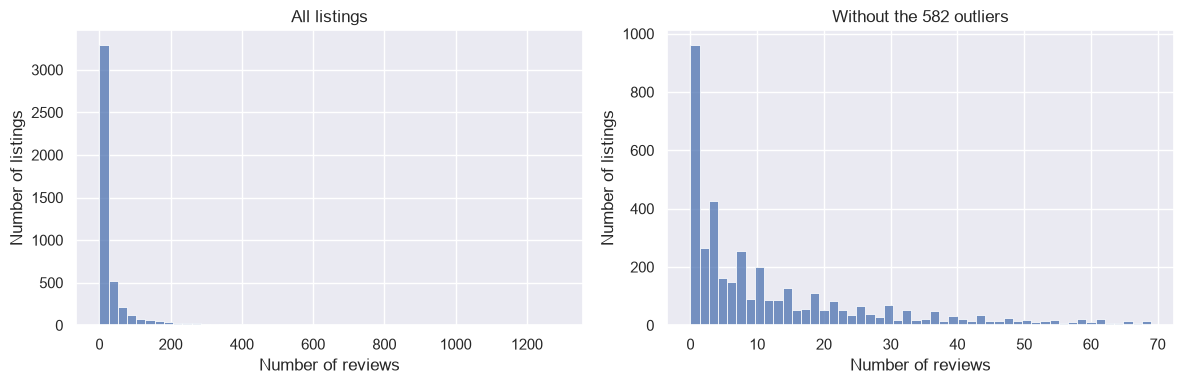

In [26]:
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)

listings['reviews_outlier'] = listings['number_of_reviews'] > upper_fence
n_outliers = listings['reviews_outlier'].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
axes[0].set_title('All listings')

sns.histplot(data=listings[~listings['reviews_outlier']], x='number_of_reviews', bins=50, ax=axes[1])
axes[1].set_title(f'Without the {n_outliers} outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

90 listings are above 300 reviews


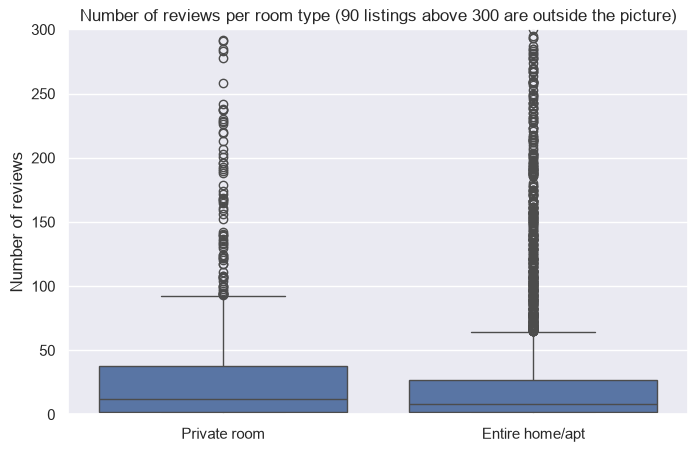

In [27]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

# Count the listings above 300 reviews (they are outside the picture)
n_outside = (two_types['number_of_reviews'] > 300).sum()
print(n_outside, 'listings are above 300 reviews')

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=two_types, x='room_type', y='number_of_reviews', ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f'Number of reviews per room type ({n_outside} listings above 300 are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('Number of reviews')

plt.show()